# Method 10 (Full Complete Pipeline): Frozen Backbone Book Context + Transformer Fine-Tuning

**Kiến trúc & Quy trình chuẩn 100%:**
1. **Backbone RT-DETRv2 (`backbone` + `frozen_ctx_proj`)**: Đóng băng hoàn toàn (`requires_grad = False`).
2. **Book Context Extraction**: Trích xuất feature maps `(P3, P4, P5)` từ backbone đóng băng, gom trung bình theo từng cuốn sách, lưu cache `float16` memmap trên `C:/doclaynet_cache/method10/` (an toàn dung lượng, không tốn RAM).
3. **Leave-One-Out & Zero-Gate Fusion**: Loại bỏ chính trang hiện tại khỏi trung bình sách khi train/eval, đi qua `ContextFusionAdapter` và cộng có trọng số `fusion_gates` vào feature map trước khi vào Transformer Encoder & Decoder.
4. **Đánh giá chính xác 100%**:
   - **Train**: 100% `train.json` (69,375 trang)
   - **Validation**: 100% `val.json` (6,489 trang) bằng `pycocotools.COCOeval` chuẩn ở mỗi epoch (không nội suy, không lấy mẫu).
   - **Test**: 100% `test.json` (4,999 trang) độc lập trên checkpoint tốt nhất.


In [1]:
import os
import sys
import json
import time
import math
import random
import shutil
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

REPO_ROOT = Path(r"d:\Semester_261\DoAnChuyenNganh\DO-AN-261")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from methods.method10.common import (
    TRAIN_ANNO, VAL_ANNO, TEST_ANNO,
    TRAIN_IMG_640, VAL_IMG_640, TEST_IMG_640,
    TRAIN_IMG_SRC, VAL_IMG_SRC, TEST_IMG_SRC,
    CACHE_DIR, WEIGHTS_DIR, REPORT_DIR,
    CATEGORIES, load_coco, book_of,
)
from methods.method10.models.rtdetr_method10 import BackboneContextRTDetrMethod10
from methods.method10.dataset import (
    precompute_backbone_book_context,
    Method10FastDataset,
    BookGroupedBatchSampler,
    collate_fn_m10,
    evaluate_method10_coco_map,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

c_free_gb = shutil.disk_usage("C:/").free / 1e9
print(f"C:/ free space: {c_free_gb:.2f} GB | CACHE_DIR: {CACHE_DIR}")

# Hyperparameters (RTX 4070 8GB optimized + Book-Grouped Batching)
BATCH_SIZE = 8
GRAD_ACCUM = 2       # Effective batch size = 16
EPOCHS = 15
LR = 5e-5
GATE_LR = 5e-4       # Higher LR & zero weight_decay for fusion_gates
MIN_LR = 5e-6
WARMUP_RATIO = 0.05
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2      # Prefetch images + reuse book_ctx in worker RAM cache
RESUME = True        # Auto-resume if last_full_method10.pt exists


C:\Users\thien\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Total VRAM: 8.59 GB
C:/ free space: 204.93 GB | CACHE_DIR: C:\doclaynet_cache\method10


In [2]:
print("Loading 100% DocLayNet COCO annotations (Train, Val, Test)...")
train_coco = load_coco(TRAIN_ANNO)
val_coco = load_coco(VAL_ANNO)
test_coco = load_coco(TEST_ANNO)

train_books = {book_of(img) for img in train_coco["images"]}
val_books = {book_of(img) for img in val_coco["images"]}
test_books = {book_of(img) for img in test_coco["images"]}

print(f"Train: {len(train_coco['images']):,} pages | {len(train_books):,} books | {len(train_coco['annotations']):,} boxes")
print(f"Val:   {len(val_coco['images']):,} pages | {len(val_books):,} books | {len(val_coco['annotations']):,} boxes")
print(f"Test:  {len(test_coco['images']):,} pages | {len(test_books):,} books | {len(test_coco['annotations']):,} boxes")

assert len(train_coco["images"]) == 69375, f"Unexpected train count: {len(train_coco['images'])}"
assert len(val_coco["images"]) == 6489, f"Unexpected val count: {len(val_coco['images'])}"
assert len(test_coco["images"]) == 4999, f"Unexpected test count: {len(test_coco['images'])}"
assert len(train_books & val_books) == 0, "Train/Val book leakage!"
assert len(train_books & test_books) == 0, "Train/Test book leakage!"
assert len(val_books & test_books) == 0, "Val/Test book leakage!"
print("Verified 100% dataset counts and zero book overlap across Train/Val/Test.")


Loading 100% DocLayNet COCO annotations (Train, Val, Test)...
Train: 69,375 pages | 2,587 books | 941,123 boxes
Val:   6,489 pages | 160 books | 99,816 boxes
Test:  4,999 pages | 196 books | 66,531 boxes
Verified 100% dataset counts and zero book overlap across Train/Val/Test.


In [3]:
model = BackboneContextRTDetrMethod10().to(device)

bb_trainable = sum(p.numel() for p in model.rtdetr.model.backbone.parameters() if p.requires_grad)
ctx_proj_trainable = sum(p.numel() for p in model.frozen_ctx_proj.parameters() if p.requires_grad)
enc_trainable = sum(p.numel() for p in model.rtdetr.model.encoder.parameters() if p.requires_grad)
dec_trainable = sum(p.numel() for p in model.rtdetr.model.decoder.parameters() if p.requires_grad)
adapter_trainable = sum(p.numel() for p in model.context_adapter.parameters() if p.requires_grad) + model.fusion_gates.numel()
total_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print(f"Frozen backbone trainable params:        {bb_trainable:,} (expected 0)")
print(f"Frozen ctx proj trainable params:        {ctx_proj_trainable:,} (expected 0)")
print(f"Trainable encoder params:                {enc_trainable:,}")
print(f"Trainable decoder params:                {dec_trainable:,}")
print(f"Trainable context_adapter + gates:       {adapter_trainable:,}")
print(f"Total trainable / Total params:          {total_trainable:,} / {total_params:,} ({100*total_trainable/total_params:.2f}%)")
assert bb_trainable == 0 and ctx_proj_trainable == 0


[Method10] Nạp pretrained RT-DETRv2 từ: docling-project/docling-layout-heron


Loading weights: 100%|██████████| 770/770 [00:00<00:00, 2848.58it/s]


[Method10] Đã đóng băng Backbone. Chỉ fine-tune Context Adapter + Projection + Transformer Encoder & Decoder.
Frozen backbone trainable params:        0 (expected 0)
Frozen ctx proj trainable params:        0 (expected 0)
Trainable encoder params:                11,031,808
Trainable decoder params:                6,931,006
Trainable context_adapter + gates:       1,967,619
Total trainable / Total params:          21,255,510 / 45,648,566 (46.56%)


In [4]:
# Precompute frozen backbone book context for Train, Val, and Test (resumable/cached on C:)
train_mmap_path, train_book_idx = precompute_backbone_book_context(
    images_list=train_coco["images"],
    img_640_dir=TRAIN_IMG_640,
    img_raw_dir=TRAIN_IMG_SRC,
    model=model,
    split="train",
    batch_size=16,
    prefix="full_",
    device=device,
)

val_mmap_path, val_book_idx = precompute_backbone_book_context(
    images_list=val_coco["images"],
    img_640_dir=VAL_IMG_640,
    img_raw_dir=VAL_IMG_SRC,
    model=model,
    split="val",
    batch_size=16,
    prefix="full_",
    device=device,
)

test_mmap_path, test_book_idx = precompute_backbone_book_context(
    images_list=test_coco["images"],
    img_640_dir=TEST_IMG_640,
    img_raw_dir=TEST_IMG_SRC,
    model=model,
    split="test",
    batch_size=16,
    prefix="full_",
    device=device,
)

train_ds = Method10FastDataset(train_coco, TRAIN_IMG_640, TRAIN_IMG_SRC, train_mmap_path, train_book_idx)
val_ds = Method10FastDataset(val_coco, VAL_IMG_640, VAL_IMG_SRC, val_mmap_path, val_book_idx)
test_ds = Method10FastDataset(test_coco, TEST_IMG_640, TEST_IMG_SRC, test_mmap_path, test_book_idx)

train_batch_sampler = BookGroupedBatchSampler(
    train_ds, batch_size=BATCH_SIZE, seed=SEED, shuffle_books=True, shuffle_pages_in_book=True
)
dl_extra = {"persistent_workers": True, "prefetch_factor": 2} if NUM_WORKERS > 0 else {}

train_loader = DataLoader(
    train_ds,
    batch_sampler=train_batch_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    collate_fn=collate_fn_m10,
    **dl_extra,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"), collate_fn=collate_fn_m10, **dl_extra,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"), collate_fn=collate_fn_m10, **dl_extra,
)
print(f"Loaders ready (Book-Grouped) | Train: {len(train_loader)} batches | Val: {len(val_loader)} batches | Test: {len(test_loader)} batches")


Precompute train book ctx (2587 books, 69375 pages): 100%|██████████| 4336/4336 [1:15:13<00:00,  1.04s/it]


[Method10 Cache] Saved train book context: 2587 books, 69375 pages in 4521.1s -> C:\doclaynet_cache\method10\full_book_ctx_train.npy


Precompute val book ctx (160 books, 6489 pages): 100%|██████████| 406/406 [06:42<00:00,  1.01it/s]


[Method10 Cache] Saved val book context: 160 books, 6489 pages in 402.5s -> C:\doclaynet_cache\method10\full_book_ctx_val.npy


Precompute test book ctx (196 books, 4999 pages): 100%|██████████| 313/313 [04:52<00:00,  1.07it/s]


[Method10 Cache] Saved test book context: 196 books, 4999 pages in 293.2s -> C:\doclaynet_cache\method10\full_book_ctx_test.npy
Loaders ready (Book-Grouped) | Train: 8672 batches | Val: 812 batches | Test: 625 batches


In [5]:
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

best_ckpt_path = WEIGHTS_DIR / "best_full_method10.pt"
last_ckpt_path = WEIGHTS_DIR / "last_full_method10.pt"
history_path = REPORT_DIR / "full_history.json"

trainable_params = [p for p in model.parameters() if p.requires_grad]
param_groups = model.get_param_groups(lr=LR, gate_lr=GATE_LR, weight_decay=WEIGHT_DECAY)
optimizer = torch.optim.AdamW(param_groups)

steps_per_epoch = max(1, math.ceil(len(train_loader) / GRAD_ACCUM))
total_opt_steps = steps_per_epoch * EPOCHS
warmup_steps = max(1, int(total_opt_steps * WARMUP_RATIO))

def lr_lambda(step: int) -> float:
    if step < warmup_steps:
        return float(step + 1) / float(warmup_steps)
    progress = float(step - warmup_steps) / float(max(1, total_opt_steps - warmup_steps))
    cosine = 0.5 * (1.0 + math.cos(math.pi * progress))
    min_ratio = MIN_LR / LR
    return min_ratio + (1.0 - min_ratio) * cosine

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

start_epoch = 1
best_map = -1.0
history = []
ep0_metrics = None

if RESUME and last_ckpt_path.exists():
    print(f"Resuming from checkpoint: {last_ckpt_path}")
    ckpt = torch.load(last_ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    try:
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    except Exception as exc:
        print(f"Note: reset optimizer/scheduler state on resume ({exc})")
    start_epoch = ckpt["epoch"] + 1
    best_map = ckpt.get("best_map", -1.0)
    history = ckpt.get("history", [])
    ep0_metrics = ckpt.get("epoch0", None)
    print(f"Resumed at epoch {start_epoch} (best_map={best_map:.4f})")

if ep0_metrics is None:
    print("Evaluating Epoch 0 (Before Fine-Tuning) on 100% Val (6,489 pages)...")
    ep0_metrics = evaluate_method10_coco_map(model, val_loader, val_coco, device, desc="Full Val Ep0 (6489)")
    print(
        f"Epoch 0 | Val mAP@[.50:.95]: {ep0_metrics['mAP']:.4f} | "
        f"AP50: {ep0_metrics['AP50']:.4f} | AP75: {ep0_metrics['AP75']:.4f} | "
        f"Time: {ep0_metrics['eval_time_sec']:.1f}s"
    )


Evaluating Epoch 0 (Before Fine-Tuning) on 100% Val (6,489 pages)...


Epoch 0 | Val mAP@[.50:.95]: 0.6430 | AP50: 0.8598 | AP75: 0.6633 | Time: 320.6s


In [6]:
for epoch in range(start_epoch, EPOCHS + 1):
    t_ep = time.time()
    train_batch_sampler.set_epoch(epoch)
    model.train()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    optimizer.zero_grad(set_to_none=True)
    loss_acc = {"loss": 0.0, "loss_vfl": 0.0, "loss_bbox": 0.0, "loss_giou": 0.0}
    n_batches = 0
    t_train_start = time.time()

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train 69,375]", leave=True)
    for step, (pixs, book_means, book_counts, labels) in enumerate(pbar, start=1):
        pixs = pixs.to(device, non_blocking=True)
        book_means = [m.to(device, non_blocking=True) for m in book_means]
        book_counts = book_counts.to(device, non_blocking=True)
        labels_dev = [
            {
                "boxes": lb["boxes"].to(device, non_blocking=True),
                "class_labels": lb["class_labels"].to(device, non_blocking=True),
            }
            for lb in labels
        ]

        with torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=(device.type == "cuda")):
            out = model(pixs, book_means, book_counts, labels=labels_dev)
            loss = out["loss"] / GRAD_ACCUM

        loss.backward()

        if step % GRAD_ACCUM == 0 or step == len(train_loader):
            torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        ld = out["loss_dict"]
        loss_acc["loss"] += float(out["loss"].detach().item())
        loss_acc["loss_vfl"] += float(ld.get("loss_vfl", 0.0))
        loss_acc["loss_bbox"] += float(ld.get("loss_bbox", 0.0))
        loss_acc["loss_giou"] += float(ld.get("loss_giou", 0.0))
        n_batches += 1

        if step % 100 == 0 or step == len(train_loader):
            pbar.set_postfix(
                loss=f"{loss_acc['loss']/n_batches:.4f}",
                vfl=f"{loss_acc['loss_vfl']/n_batches:.4f}",
                lr=f"{optimizer.param_groups[0]['lr']:.2e}",
            )

    train_time = time.time() - t_train_start
    train_fps = len(train_coco["images"]) / max(train_time, 1e-6)

    # Exact COCO evaluation on 100% Validation (6,489 pages)
    val_metrics = evaluate_method10_coco_map(model, val_loader, val_coco, device, desc=f"Epoch {epoch} [Val 6489]")
    gates = [round(float(g), 5) for g in model.fusion_gates.detach().cpu().tolist()]
    peak_vram = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0.0
    ep_time = time.time() - t_ep

    row = {
        "epoch": epoch,
        "train_loss": loss_acc["loss"] / max(n_batches, 1),
        "loss_vfl": loss_acc["loss_vfl"] / max(n_batches, 1),
        "loss_bbox": loss_acc["loss_bbox"] / max(n_batches, 1),
        "loss_giou": loss_acc["loss_giou"] / max(n_batches, 1),
        "val_mAP": val_metrics["mAP"],
        "val_AP50": val_metrics["AP50"],
        "val_AP75": val_metrics["AP75"],
        "val_APs": val_metrics["AP_small"],
        "val_APm": val_metrics["AP_medium"],
        "val_APl": val_metrics["AP_large"],
        "per_class": val_metrics["per_class"],
        "fusion_gates": gates,
        "lr": optimizer.param_groups[0]["lr"],
        "peak_vram_gb": round(peak_vram, 2),
        "train_fps": round(train_fps, 2),
        "val_eval_sec": val_metrics["eval_time_sec"],
        "epoch_time_sec": round(ep_time, 1),
    }
    history.append(row)

    print(
        f"Epoch {epoch}/{EPOCHS} | Loss: {row['train_loss']:.4f} "
        f"(VFL={row['loss_vfl']:.4f}, Bbox={row['loss_bbox']:.4f}, GIoU={row['loss_giou']:.4f}) | "
        f"Val mAP: {row['val_mAP']:.4f} | AP50: {row['val_AP50']:.4f} | AP75: {row['val_AP75']:.4f} | "
        f"Gates: {gates} | VRAM: {peak_vram:.2f} GB | {train_fps:.1f} img/s | Time: {ep_time:.1f}s"
    )

    if val_metrics["mAP"] > best_map:
        best_map = val_metrics["mAP"]
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "val_metrics": val_metrics,
                "fusion_gates": gates,
            },
            best_ckpt_path,
        )
        print(f"  -> Saved new BEST checkpoint (Val mAP={best_map:.4f}) -> {best_ckpt_path}")

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_map": best_map,
            "history": history,
            "epoch0": ep0_metrics,
        },
        last_ckpt_path,
    )

    with open(history_path, "w", encoding="utf-8") as f:
        json.dump({"epoch0": ep0_metrics, "history": history}, f, indent=2)


Epoch 1/15 [Train 69,375]: 100%|██████████| 8672/8672 [1:29:09<00:00,  1.62it/s, loss=9.6174, lr=5.00e-05, vfl=0.5489]  


Epoch 1/15 | Loss: 9.6174 (VFL=0.5489, Bbox=0.0316, GIoU=0.1335) | Val mAP: 0.7720 | AP50: 0.9290 | AP75: 0.8476 | Gates: [0.00129, -0.12352, 0.14884] | VRAM: 4.03 GB | 13.0 img/s | Time: 5686.8s
  -> Saved new BEST checkpoint (Val mAP=0.7720) -> D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\method10\weights\best_full_method10.pt


Epoch 2/15 [Train 69,375]: 100%|██████████| 8672/8672 [1:15:32<00:00,  1.91it/s, loss=7.9304, lr=4.92e-05, vfl=0.4862]


Epoch 2/15 | Loss: 7.9304 (VFL=0.4862, Bbox=0.0287, GIoU=0.1175) | Val mAP: 0.7851 | AP50: 0.9308 | AP75: 0.8621 | Gates: [-0.03617, -0.14486, 0.18532] | VRAM: 3.98 GB | 15.3 img/s | Time: 4793.3s
  -> Saved new BEST checkpoint (Val mAP=0.7851) -> D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\method10\weights\best_full_method10.pt


Epoch 3/15 [Train 69,375]: 100%|██████████| 8672/8672 [1:10:38<00:00,  2.05it/s, loss=7.5587, lr=4.73e-05, vfl=0.4611]


Epoch 3/15 | Loss: 7.5587 (VFL=0.4611, Bbox=0.0273, GIoU=0.1114) | Val mAP: 0.7785 | AP50: 0.9356 | AP75: 0.8609 | Gates: [-0.0267, -0.17804, 0.21056] | VRAM: 4.03 GB | 16.4 img/s | Time: 4502.7s


... (4 outputs left out)

Epoch 6/15 [Train 69,375]: 100%|██████████| 8672/8672 [1:19:39<00:00,  1.81it/s, loss=6.9159, lr=3.65e-05, vfl=0.4130]


Epoch 6/15 | Loss: 6.9159 (VFL=0.4130, Bbox=0.0249, GIoU=0.1011) | Val mAP: 0.7344 | AP50: 0.9306 | AP75: 0.8281 | Gates: [-0.10831, -0.27266, 0.25123] | VRAM: 4.03 GB | 14.5 img/s | Time: 5047.5s


Epoch 7/15 [Train 69,375]:   1%|          | 59/8672 [00:30<1:13:56,  1.94it/s]


KeyboardInterrupt: 

In [7]:
print(f"Loading best checkpoint from {best_ckpt_path} for 100% Test Evaluation (4,999 pages)...")
best_ckpt = torch.load(best_ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(best_ckpt["model_state_dict"])

test_metrics = evaluate_method10_coco_map(model, test_loader, test_coco, device, desc="Test 100% (4,999)")
test_fps = len(test_coco["images"]) / max(test_metrics["eval_time_sec"], 1e-6)
test_metrics["test_fps"] = round(test_fps, 2)
test_metrics["best_val_epoch"] = best_ckpt["epoch"]
test_metrics["best_val_mAP"] = best_ckpt["val_metrics"]["mAP"]

with open(REPORT_DIR / "test_results_method10.json", "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2)

print("=" * 70)
print(f"METHOD 10 FINAL TEST RESULTS (100% Test = {test_metrics['num_images']} pages)")
print("=" * 70)
print(f"Best Val Epoch:   {test_metrics['best_val_epoch']} (Val mAP = {test_metrics['best_val_mAP']:.4f})")
print(f"Test mAP@[.50:.95]: {test_metrics['mAP']:.4f}")
print(f"Test AP50:          {test_metrics['AP50']:.4f}")
print(f"Test AP75:          {test_metrics['AP75']:.4f}")
print(f"Test AP_small:      {test_metrics['AP_small']:.4f}")
print(f"Test AP_medium:     {test_metrics['AP_medium']:.4f}")
print(f"Test AP_large:      {test_metrics['AP_large']:.4f}")
print(f"Eval Speed:         {test_fps:.2f} img/s ({test_metrics['eval_time_sec']:.1f}s)")
print("-" * 70)
print("Per-Class Test AP@[.50:.95]:")
for cls_name, ap in test_metrics["per_class"].items():
    print(f"  {cls_name:<18}: {ap:.4f}")


Loading best checkpoint from D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\method10\weights\best_full_method10.pt for 100% Test Evaluation (4,999 pages)...


METHOD 10 FINAL TEST RESULTS (100% Test = 4999 pages)
Best Val Epoch:   2 (Val mAP = 0.7851)
Test mAP@[.50:.95]: 0.7829
Test AP50:          0.9251
Test AP75:          0.8497
Test AP_small:      0.5839
Test AP_medium:     0.6845
Test AP_large:      0.8359
Eval Speed:         24.48 img/s (204.2s)
----------------------------------------------------------------------
Per-Class Test AP@[.50:.95]:
  Caption           : 0.7755
  Footnote          : 0.7770
  Formula           : 0.6767
  List-item         : 0.8544
  Page-footer       : 0.6702
  Page-header       : 0.7556
  Picture           : 0.8122
  Section-header    : 0.7269
  Table             : 0.8782
  Text              : 0.8824
  Title             : 0.8026


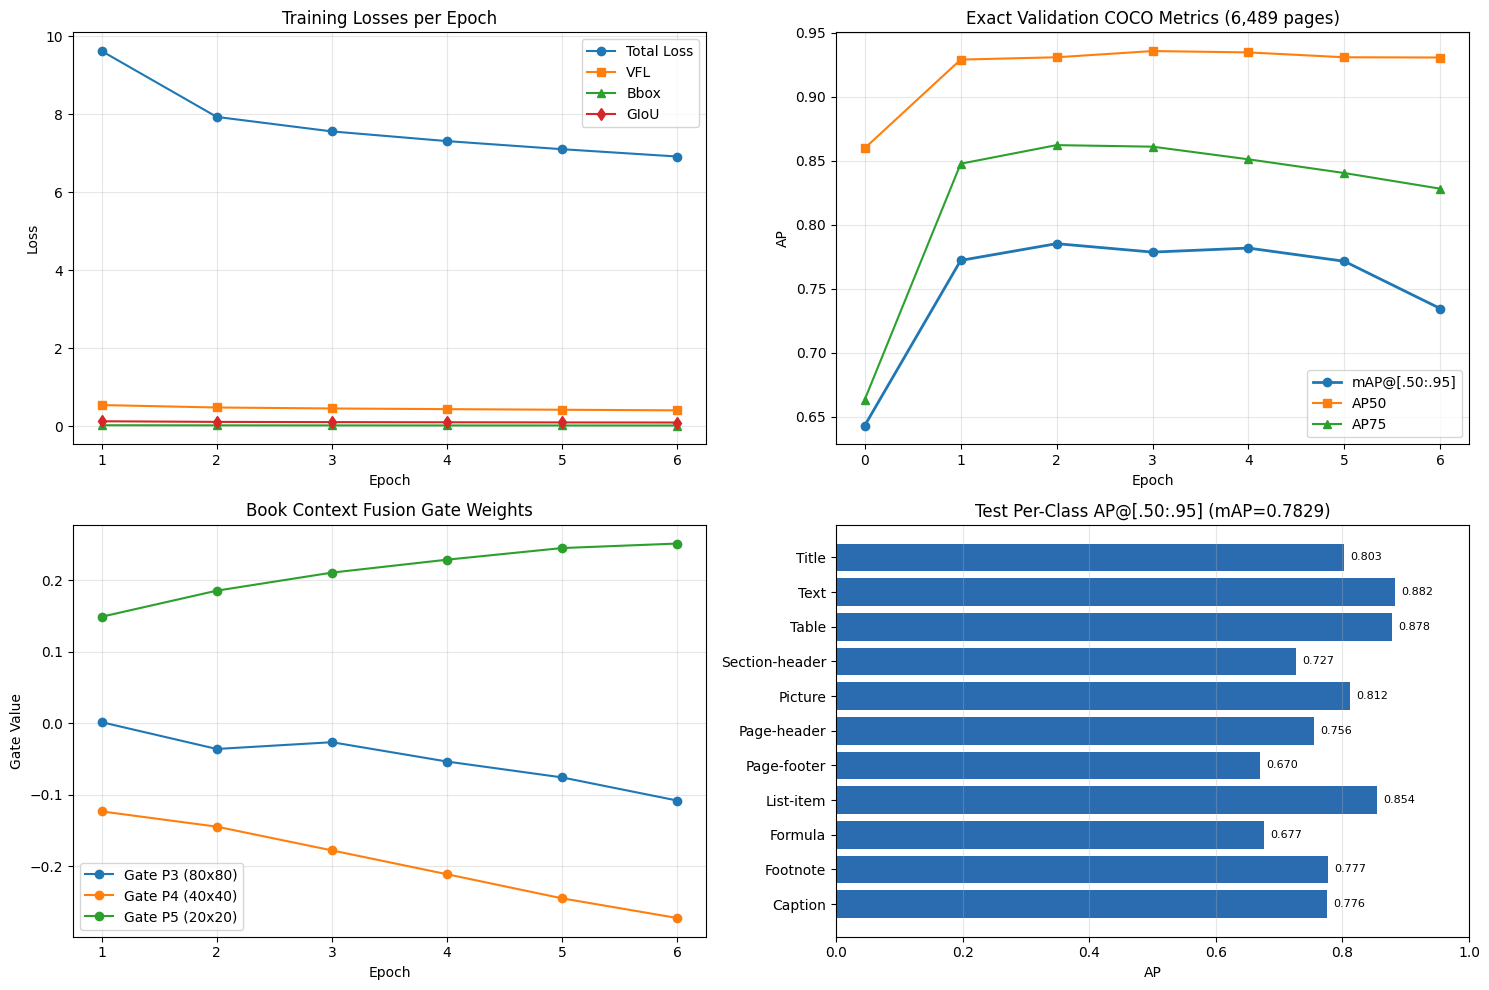

Saved charts to D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\method10\report\method10_full_charts.png


In [8]:
epochs_x = [0] + [h["epoch"] for h in history]
maps_y = [ep0_metrics["mAP"]] + [h["val_mAP"] for h in history]
ap50_y = [ep0_metrics["AP50"]] + [h["val_AP50"] for h in history]
ap75_y = [ep0_metrics["AP75"]] + [h["val_AP75"] for h in history]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Training Losses
axes[0, 0].plot([h["epoch"] for h in history], [h["train_loss"] for h in history], marker="o", label="Total Loss")
axes[0, 0].plot([h["epoch"] for h in history], [h["loss_vfl"] for h in history], marker="s", label="VFL")
axes[0, 0].plot([h["epoch"] for h in history], [h["loss_bbox"] for h in history], marker="^", label="Bbox")
axes[0, 0].plot([h["epoch"] for h in history], [h["loss_giou"] for h in history], marker="d", label="GIoU")
axes[0, 0].set_title("Training Losses per Epoch")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Validation COCO mAP (100% Val = 6,489 pages)
axes[0, 1].plot(epochs_x, maps_y, marker="o", linewidth=2, label="mAP@[.50:.95]")
axes[0, 1].plot(epochs_x, ap50_y, marker="s", label="AP50")
axes[0, 1].plot(epochs_x, ap75_y, marker="^", label="AP75")
axes[0, 1].set_title("Exact Validation COCO Metrics (6,489 pages)")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("AP")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Fusion Gates Evolution
for s_idx, s_name in enumerate(["Gate P3 (80x80)", "Gate P4 (40x40)", "Gate P5 (20x20)"]):
    axes[1, 0].plot([h["epoch"] for h in history], [h["fusion_gates"][s_idx] for h in history], marker="o", label=s_name)
axes[1, 0].set_title("Book Context Fusion Gate Weights")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Gate Value")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Per-Class Test AP Bar Chart
cls_names = list(test_metrics["per_class"].keys())
cls_aps = [test_metrics["per_class"][c] for c in cls_names]
bars = axes[1, 1].barh(cls_names, cls_aps, color="#2b6cb0")
axes[1, 1].set_xlim(0, 1.0)
axes[1, 1].set_title(f"Test Per-Class AP@[.50:.95] (mAP={test_metrics['mAP']:.4f})")
axes[1, 1].set_xlabel("AP")
axes[1, 1].grid(True, axis="x", alpha=0.3)
for bar, v in zip(bars, cls_aps):
    axes[1, 1].text(v + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center", fontsize=8)

plt.tight_layout()
fig_path = REPORT_DIR / "method10_full_charts.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved charts to {fig_path}")
